# Weather Hazard Category · Dummy Classifier

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Experiment notebook · predicts WHC exactly +7 days ahead*

This notebook develops the **Dummy Classifier** model for the **Weather Hazard Category (WHC)**: pipeline stages 1-2, using the leakage-audited feature matrix produced by the preprocessing notebook.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

### Hypothesis

`DummyClassifier(strategy="most_frequent")` ignores the features and predicts the most common
training class every day. It is the correct **null model**: every other hazard experiment must
beat it.

The hypothesis governs how every other hazard notebook is read: **this model will have the
highest accuracy in the project and close to the lowest macro F1.** If that holds, accuracy is
disqualified as a selection metric for this target by measurement, not by assertion.

It also defines what a *collapsed* model looks like: any classifier whose confusion matrix
resembles this one has fallen back to the majority class, whatever it cost to train.

### Design

| Choice | Value | Reason |
|:--|:--|:--|
| Algorithm | `DummyClassifier(strategy="most_frequent")` | sklearn's standard majority-class null model |
| Features | Received, then ignored | The rule does not depend on `X` |
| Scaling | None | A class-count rule is unaffected by feature scale |
| Strategy | One classifier for the single +7 day horizon | Matches the deployed artefact layout |
| Selection | `default_params` only; never tuned or shortlisted | A null model is the floor, not a candidate |
| Objective | validation **macro F1** (higher is better), averaged over the walk-forward folds | Used for every comparison |

### Where this notebook sits in the pipeline

| Stage | What happens | Where |
|:-:|:--|:--|
| 1–2 | Baselines, ablation and hyperparameter tuning on all features | **This notebook** |
| 3 | Shortlist the best tuned algorithms | Comparison notebook |
| 4 | Feature selection for the shortlist, then a short re-tune | Comparison notebook |
| 5–6 | Choose the champion; refit it on all development data | Comparison notebook |
| 7 | Score the champion once on the test split (2025) | Comparison notebook |
| 8 | Deploy with drift monitoring | Promotion + API |

Every score in this notebook is a **walk-forward cross-validation** average: the development split
(2016–2024) is divided into four expanding-window folds that validate on 2021, 2022, 2023 and 2024
in turn, with the embargo as a gap. A setting therefore has to work across four years, not one. The
test split is never loaded here.

### Workflow

All ten experiment notebooks run the same code from `nucleus_ml.weather.Experiment`, so their results are directly comparable. **Only the model specification in section 1 differs between notebooks.**

| # | Step | Purpose |
|:-:|:--|:--|
| 1 | Model specification | The only algorithm-specific cell |
| 2 | Data and folds | The development split and its walk-forward folds |
| 3 | Baselines | Stage 1: the floor every model must clear |
| 4 | Feature-family ablation | What each block of engineered features contributes |
| 5 | Cross-validated results | The model against its default and the baselines |
| 6 | Feature importance | Which features the model relies on |
| 7 | Generalisation check | Training vs validation performance |
| 8 | Save the experiment bundle | Model, CV results and specification |
| 9 | Conclusions | What to carry into the report |

---
## 0. Setup

Imports, the experiment's identity and the task definition. Everything else comes from the project package.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.dummy import DummyClassifier

from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "weather_hazard"
EXPERIMENT = "whc_dummy"
ALGORITHM = "Dummy Classifier"
VERBOSE = 1  # 0 = results only, 1 = progress + every Optuna trial, 2 = every model fit

task = wx.load_task(TASK)
print(f"{task.target_name} | {ALGORITHM} | {len(task.feature_columns)} features | "
      f"targets: {task.target_columns}")

Weather Hazard Category | Dummy Classifier | 105 features | targets: ['whc_t7']


---
## 1. Model specification

This is the **only algorithm-specific cell**. It creates the experiment from the estimator class, which the package builds (seeding it and, where requested, scaling the features), so no helper function is needed. It also sets the configuration the model always uses (`default_params`).

The model has a single setting, `strategy="most_frequent"`, which is used as is. A majority-class
rule has no parameters worth tuning, and fixing it keeps the floor a property of the labels
rather than of a search.

In [2]:
exp = wx.Experiment(
    task,
    name=EXPERIMENT,
    algorithm=ALGORITHM,
    verbose=VERBOSE,
    estimator=DummyClassifier,
    default_params={"strategy": "most_frequent"},  # used as is: no search in this notebook
)

[whc_dummy] loaded 3,251 development rows; 4 walk-forward folds; 105 features; metric macro_f1 (higher is better)


---
## 2. Data and folds

Only the **development split** (`train`, 2016–2024) is loaded. The table lists the
walk-forward folds: each trains on every year before its validation year, with the
embargo between them.

> The preprocessing notebook already applied the chronological split, the warm-up
> filter and the embargo before the test period. Nothing is shuffled here.

In [3]:
exp.data_summary()

,train_start,train_end,validate_start,validate_end,train_rows,validate_rows,validate_Low Risk,validate_Moderate Risk,validate_High Risk,validate_Extreme Risk
fold,,,,,,,,,,
1,2016-01-31,2020-12-18,2020-12-26,2021-12-25,1784,365,172.000,178.000,14.000,1.000
2,2016-01-31,2021-12-18,2021-12-26,2022-12-25,2149,365,150.000,189.000,24.000,2.000
3,2016-01-31,2022-12-18,2022-12-26,2023-12-25,2514,365,209.000,146.000,10.000,0.000
4,2016-01-31,2023-12-18,2023-12-26,2024-12-24,2879,365,167.000,183.000,15.000,0.000


---
## 3. Baselines

Three naive forecasts, refitted on the training years of every fold and scored on its
validation year (the table shows the mean over the folds):

| Baseline | Rule | What it knows |
|:--|:--|:--|
| **Majority class** | Always predict the most common class | Nothing but the class balance |
| **Persistence** | The class in 7 days equals today's class (from today's WHI) | The current weather |
| **Seasonal mode** | The most common class for that month | The season |

The majority-class rule scores a high *accuracy* but a low *macro F1*, which is exactly why
accuracy is not used to select models for this imbalanced target.

In [4]:
exp.run_baselines()

[whc_dummy] baseline majority_class  whc_t7: mean macro_f1 = 0.1612
[whc_dummy] baseline persistence     whc_t7: mean macro_f1 = 0.2546
[whc_dummy] baseline seasonal_mode   whc_t7: mean macro_f1 = 0.2742


accuracy  balanced_accuracy  macro_f1  weighted_f1  \
target model                                                                
whc_t7 majority_class     0.478              0.292     0.161        0.311   
       persistence        0.468              0.295     0.255        0.468   
       seasonal_mode      0.541              0.329     0.274        0.527   

                       mean_ordinal_error  
target model                               
whc_t7 majority_class               0.569  
       persistence                  0.577  
       seasonal_mode                0.486

---
## 4. Feature-family ablation

Feature families are added **one at a time**, starting from persistence alone, and the model is cross-validated at each step with `ablation_params`. This *measures* what each block of engineering contributes; choosing features happens later, in the comparison notebook. Scores are mean macro F1 over the folds.

> A null model ignores its inputs, so every row should score the same: this confirms the model does not use `X`.

[whc_dummy] ablation: 9 feature sets x 1 target(s) x 4 folds
[whc_dummy] ablation persistence only (whi)              whc_t7: macro_f1 = 0.1612 (1 features)
[whc_dummy] ablation + same_day_observations             whc_t7: macro_f1 = 0.1612 (6 features)
[whc_dummy] ablation + same_day_indices                  whc_t7: macro_f1 = 0.1612 (17 features)
[whc_dummy] ablation + lags                              whc_t7: macro_f1 = 0.1612 (49 features)
[whc_dummy] ablation + rolling_statistics                whc_t7: macro_f1 = 0.1612 (89 features)
[whc_dummy] ablation + rolling_precipitation             whc_t7: macro_f1 = 0.1612 (93 features)
[whc_dummy] ablation + rolling_gusts                     whc_t7: macro_f1 = 0.1612 (97 features)
[whc_dummy] ablation + deltas                            whc_t7: macro_f1 = 0.1612 (103 features)
[whc_dummy] ablation + seasonal                          whc_t7: macro_f1 = 0.1612 (105 features)


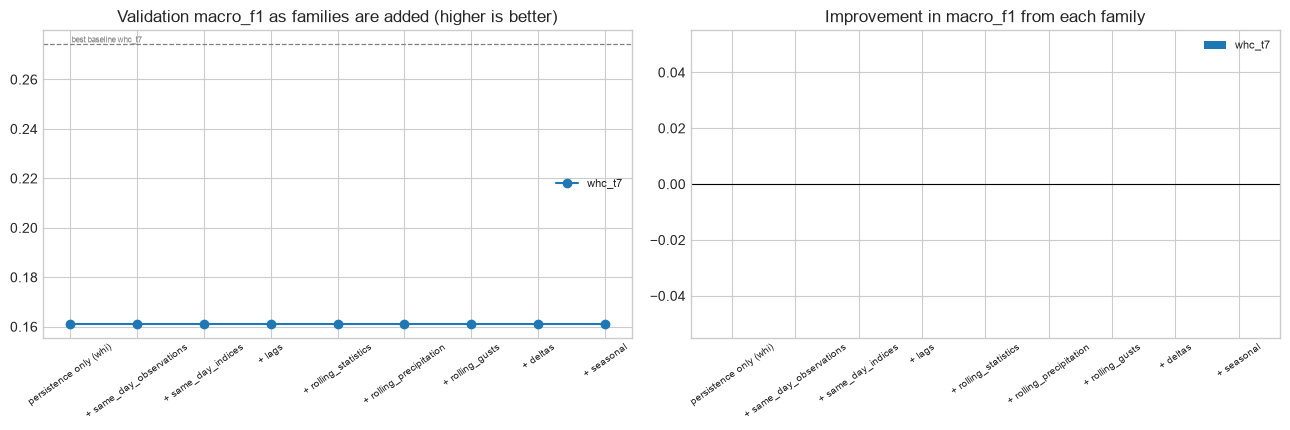

target,whc_t7,n_features
config,,
persistence only (whi),0.161,1
+ same_day_observations,0.161,6
+ same_day_indices,0.161,17
+ lags,0.161,49
+ rolling_statistics,0.161,89
+ rolling_precipitation,0.161,93
+ rolling_gusts,0.161,97
+ deltas,0.161,103
+ seasonal,0.161,105


In [5]:
ablation = exp.run_ablation()
plt.show()
ablation

---
## 5. Cross-validated results

The chosen configuration is cross-validated again and compared with every baseline, all on the same folds. `gain_of_model` is positive when the model beats that row. The plot shows the **out-of-fold predictions**: every validation year predicted by a model that never saw it.

Read the **confusion matrix** as well as the headline score: a model that almost never predicts
the rare classes has not learned to flag hazardous days, whatever its macro F1. The printed
boundary summary shows how many errors sit within a few WHI points of a class threshold; those are
threshold effects rather than genuine misses.

In [6]:
exp.assess()

[whc_dummy] assess whc_t7: default mean macro_f1 = 0.1612 (best baseline 0.2742)


accuracy  balanced_accuracy  macro_f1  weighted_f1  \
target model                                                                
whc_t7 default            0.478              0.292     0.161        0.311   
       majority_class     0.478              0.292     0.161        0.311   
       persistence        0.468              0.295     0.255        0.468   
       seasonal_mode      0.541              0.329     0.274        0.527   

                       mean_ordinal_error  train_macro_f1  gain_of_model  
target model                                                              
whc_t7 default                      0.569           0.167          0.000  
       majority_class               0.569             NaN          0.000  
       persistence                  0.577             NaN         -0.093  
       seasonal_mode                0.486             NaN         -0.113

Misclassification vs class boundaries: {'misclassified': 762, 'of_days': 1460, 'median_distance_to_boundary': 5.765000000000006, 'share_within_5_points': 0.4461942257217848}


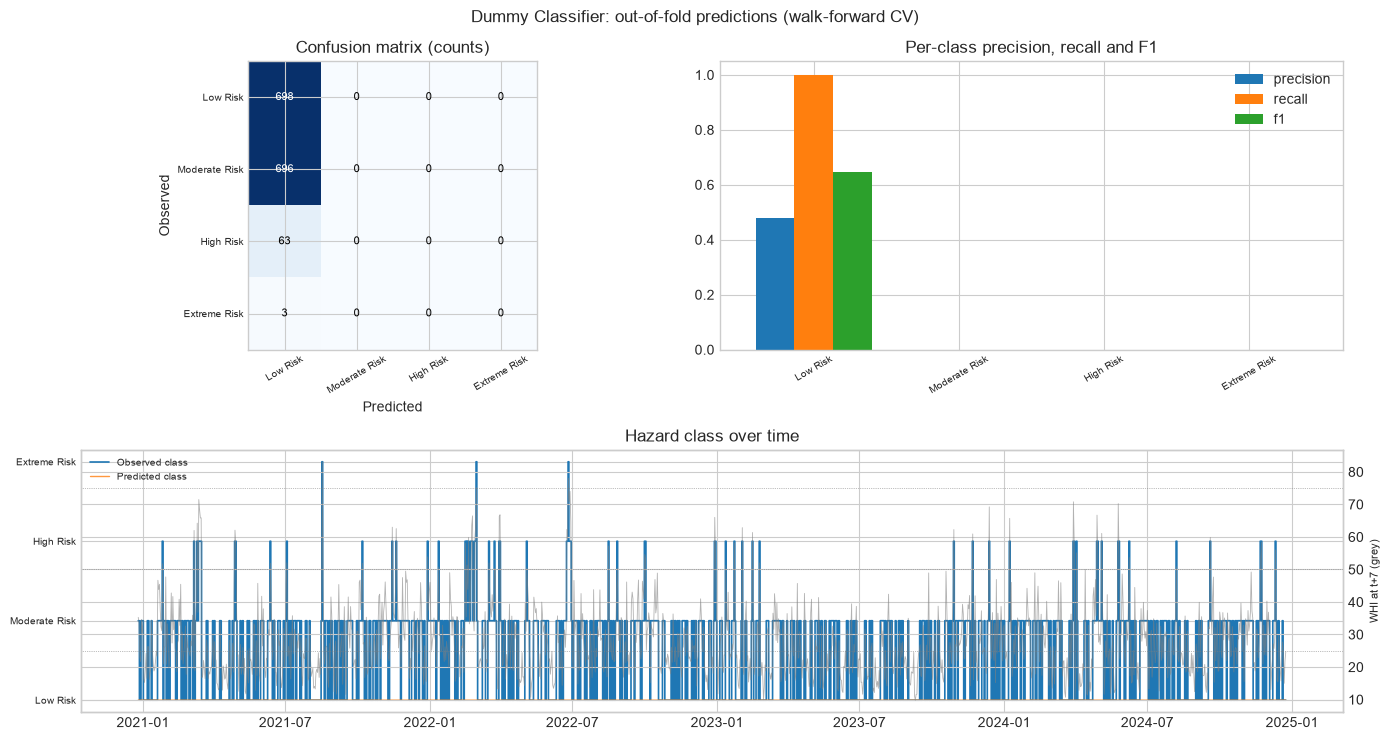

In [7]:
exp.plot_validation()
plt.show()

---
## 6. Feature importance

A dummy model ignores the features, so there is no importance to report.

> Importance is measured on the last fold's model and validation year (2024). Correlated features share importance, so the ablation in section 4 is the better guide to what can be removed.

In [8]:
family_importance = exp.importance()
plt.show()
family_importance

[whc_dummy] computing feature importance (permutation importance can take a while)
No feature importance: this estimator ignores the features.


---
## 7. Generalisation check

Mean training and validation scores over the folds. A small gap means the model
generalises; a large gap means it memorises the training years.

In [9]:
exp.generalisation()

,train_macro_f1,validation_macro_f1,validation_minus_train
target,,,
whc_t7,0.167,0.161,-0.006


---
## 8. Save the experiment bundle

The chosen configuration is refitted on **all development data** and saved to
`models/weather_hazard/experiments/whc_dummy/`:

| File | Contents |
|:--|:--|
| `whc_dummy_h<horizon>.joblib` | The model, one per horizon |
| `metadata.json` | Settings, features, importance and the cross-validated scores |
| `manifest.json` | File list and the feature column order |
| `spec.joblib` | The specification and tuned settings, which the comparison notebook uses to rebuild this experiment |

In [10]:
exp.export()

[whc_dummy] final fit whc_t7: 3,251 rows, 105 features
Saved bundle: models/weather_hazard/experiments/whc_dummy


PosixPath('/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/models/weather_hazard/experiments/whc_dummy')

---
## 9. Conclusions

- **This is the floor, not the bar.** Persistence and the seasonal mode use information and should
  beat it; the gap measures what current weather and the calendar are each worth.
- **The metric argument, measured.** Report this model's accuracy and macro F1 side by side
  (section 5). One near the majority share and one near the floor is the clearest
  justification for not optimising accuracy on this target.
- **The collapse test.** Compare the other four confusion matrices with this one before reporting
  any of them as successful.

> A null model is never shortlisted: it has nothing to tune and exists only as the floor.

> The test split has still not been used. It is scored exactly once, in the `whc_comparison` notebook, after the champion has been chosen.